# YZM411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Öğrenci:** Umut Barbaros BABAHAN — 230212065

| | |
|---|---|
| **Girdi dosyaları** | `veri/normal.jpg`, `veri/golge.jpg`, `veri/lamba.jpg` (kendi çekimim, sabit kamera ve nesne konumu) |
| **Çıktılar** | `sonuclar/` klasörü: şekiller, 6 maske, ham ölçüm CSV'leri, `sonuc_tablosu.csv`, `parametreler.json` |
| **Çalışma ortamı** | **Colab:** Drive otomatik bağlanır, proje klasörü `/content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme` (fotoğraflar `veri/` alt klasöründe). **Yerel (VS Code / Jupyter):** defterin bulunduğu klasör, fotoğraflar `veri/` içinde. Klasör 0.1'deki `COLAB_PROJE` ile değiştirilebilir. |
| **Çalıştırma sırası** | *Kernel → Restart & Run All* (Colab: *Çalışma zamanı → Tümünü çalıştır*). Hücreler yukarıdan aşağı sırayla çalışır. |
| **Paket sürümleri** | Bölüm 0.3'te yazdırılır ve `parametreler.json`'a kaydedilir. |

**Kural:** Bölüm 0.1 (Ayarlar) ve 0.2 (Tahminler) deneyler çalıştırılmadan **önce** doldurulur. Tahmini boş bırakılan deney hücresi hata verip durur — tahmini olmayan deney puanlanmaz.

İlk çalıştırmada koordinatlar boş olduğu için defter Bölüm 1.2'de durur: ızgaralı görüntüden piksel ve bölge koordinatlarını okuyup 0.1'e yazın, sonra yeniden *Run All* yapın.

## 0. Ayarlar, tahminler, ortam
### 0.1 Ayarlar — bütün parametreler yalnızca bu hücrede

In [ ]:
import os, sys
from pathlib import Path

# --- Proje klasörü: Colab'da Google Drive, yerelde (VS Code / Jupyter) defterin bulunduğu klasör ---
COLAB_PROJE = Path("/content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme")   # Colab'da kullanılacak Drive klasörü
COLAB = "google.colab" in sys.modules

if os.environ.get("YZM411_PROJE"):                  # isteğe bağlı: ortam değişkeniyle başka klasör
    PROJE = Path(os.environ["YZM411_PROJE"])
elif COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    PROJE = COLAB_PROJE
else:
    PROJE = Path.cwd()                              # yerel: defterin çalıştığı klasör

DOSYALAR = {"normal": "normal.jpg", "golge": "golge.jpg", "lamba": "lamba.jpg"}

# Fotoğraflar PROJE/veri/ içindeyse orası; doğrudan PROJE içindeyse PROJE kullanılır.
VERI = PROJE / "veri"
if not VERI.exists() and all((PROJE / d).exists() for d in DOSYALAR.values()):
    VERI = PROJE
CIKTI = PROJE / "sonuclar"                          # çıktılar da aynı klasöre (Colab'da Drive'a) yazılır

print("Ortam      :", "Google Colab" if COLAB else "yerel")
print("Proje      :", PROJE)
print("Veri       :", VERI, "(var)" if VERI.exists() else "(YOK — fotoğrafları buraya koyun)")
print("Çıktılar   :", CIKTI)

# Kamera durumu: otomatik pozlama / beyaz dengesi açıksa "yalnızca ışık değişti" denemez.
KAMERA_NOTU = {
    "cihaz": "SAMSUNG S20 FE, arka kamera, 12 MP",                     # ör. "Telefon modeli, arka kamera, 12 MP"
    "otomatik_pozlama": False,        # True / False
    "otomatik_beyaz_dengesi": False,  # True / False
    "aciklama": "Pro modda ISO 200, 26mm, 0.0v, F1.8, 1/30 s, WB 5000K kilitlendi",   # ör. "Pro modda ISO 100, 1/60 s, WB 5000K kilitlendi"
    "isik_kosullari": {"normal": "", "golge": "", "lamba": ""},  # ör. "pencere ışığı", "kitapla gölge", "sarı masa lambası"
}

# Koordinatlar piksel cinsindendir: nokta (x, y), bölge (x, y, w, h). Bölüm 1.2'deki ızgaralı görüntüden okuyun.
PIKSELLER  = [(1560, 1100), (1565, 1150), (1570, 1200)]  # nesne üzerinde aynı fiziksel bölgeden 3 piksel, ör. [(1520, 980), (1560, 1000), (1490, 960)]
NESNE_ROI  = (1540, 1080, 50, 100)   # eşik seçimi için nesne üzerinde KÜÇÜK bölge, ör. (1480, 940, 120, 90)
NESNE_KUTU = (1468, 897, 240, 450) # nesnenin TAMAMINI çevreleyen kutu; yalnızca "nesne dışında seçilen piksel" sayımı için
KAGIT_ROI  = (2200, 1800, 200, 200)   # beyaz/gri kâğıt üzerinde küçük bölge; ışığın rengini izlemek için
YAZI_ROI   = (650, 950, 400, 400)    # küçük yazı / çizgili doku bölgesi (küçültme deneyi)
YAZI_HARF_YUKSEKLIGI_PX = 8  # özgün görüntüde küçük harf yüksekliği (Bölüm 4'teki yakın plandan ölçün)

# Renk eşikleri. None bırakılırsa NESNE_ROI'den YALNIZCA normal fotoğrafta bir kez hesaplanır ve dondurulur.
# Şeffaflık için: önerilen değerleri Bölüm 2.1 çıktısından kopyalayıp buraya yazmanız önerilir.
ESIK_RGB = {"R": (168, 255), "G": (0, 13), "B": (0, 55)}
ESIK_HSV = {"H": (169, 179), "S": (241, 255), "V": (60, 255)}
# Otomatik öneri biçimi (ödevdeki örnekle aynı): RGB'de parlak kanal için "> alt", koyu kanal için "< üst";
# HSV'de H için aralık, S için "> alt", V için sabit gevşek alt sınır (tonu ölçmek, parlaklığı ölçmemek için).
ESIK_YUZDELIK = (2, 98)  # otomatik öneride kullanılan yüzdelikler
ESIK_PAY = 10            # R, G, B, S sınırlarına eklenen pay
ESIK_PAY_H = 4           # H sınırlarına eklenen pay
ESIK_V_ALT = 60          # HSV önerisinde V alt sınırı (çok karanlık pikselleri dışarıda bırakır)

PARLAKLIK_B = 40
GAMALAR = [0.5, 2.0]     # bu ödevde γ formüldeki üstür: J = 255·(I/255)^γ
OLCEK = 4                # genişlik ve yükseklikte 1/4 küçültme

Ortam      : Google Colab
Proje      : /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme
Veri       : /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/veri (var)
Çıktılar   : /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar


In [51]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 0.2 Tahminler — deneyleri çalıştırmadan ÖNCE yazın
Her deney için iki cümle: *hangi ayrıntı veya hata değişecek, neden?* Sayısal tahminler sonuç tablosunda ölçümle yan yana konur.

In [52]:
TAHMINLER = {
    "D4_sayisal_yapi":   '''Telefon JPG’si 8 bit kaydedildiği için dizi (H, W, 3) boyutunda (1024, 768, 3), uint8 türünde ve 0–255 aralığında olacak.
                            Sarı/kırmızımsı lambada kırmızı oyuncak arabanın R kanalı zaten nesneyle aynı dalga boyunda olduğu için yüksek kalacak
                            ancak G ve B kanalları çok daha fazla düşecek; ayrıca lambanın sıcak ışığı beyaz kağıt ve masa yüzeyindeki R değerlerini de artırarak
                            araba ile arka plan arasındaki R farkını azaltacak.''',
    "D5_renk_esikleri":  '''Gölgede üç kanal birlikte düşeceği için arabanın R değeri sabit RGB eşiğinin alt sınırının altına inecek ve RGB maskesi büyük ölçüde boşalacak.
                            HSV uzayında kırmızı renk 0/179 ton (Hue) sınırında ikiye bölündüğü için tek bir dar aralık kullanılırsa normalde bile piksellerin bir kısmı kaçabilir;
                            gölgede parlaklık düşse de ton korunduğu için HSV maskesi RGB'ye göre daha az küçülecek. Ancak lambanın ışığı nesneyle aynı tonda olduğundan,
                            lamba altında beyaz kağıt ve masa yansıması da kırmızı/turuncu tona kayıp HSV eşiğine girecek; bu yüzden lamba altında HSV maskesi küçülmek yerine
                            arka planı da kapsayarak büyüyecek veya yüksek doygunlukla arabanın tamamını tutmaya devam edecek.''',
    "D6a_parlaklik_b40": '''b = +40: “Ortalama 71'den 111'e çıkmalı; görüntünün büyük kısmı koyu masa yüzeyi olduğu için kırpılma az olacak,
                            sadece sağdaki beyaz kağıdın 255'e yakın pikselleri kırpılacağı için artış 40'ın biraz altında, yaklaşık +37 olacak (ölçülen yeni ortalama ≈ 108).''',
    "D6b_gama_0_5":      '''γ = 0,5: “Formüle göre 255 * (71/255)^{0,5} = 134 olduğu için ortalamanın yaklaşık +63 artmasını bekleriz;
                            ancak görüntünün çoğu çok koyu piksellerden ve bir kısmı parlak beyaz kağıttan oluştuğu için iki uçtaki pikseller orta tonlar
                            kadar artmayacak ve gerçek ortalama artışı daha düşük çıkacak.''',
    "D6c_gama_2_0":      '''γ = 2,0: “Formüle göre 255 * (71/255)^2 = 20 olduğu için ortalamanın yaklaşık −51 düşmesi beklenir;
                            fakat ortalamanın gaması ile gamanın ortalaması aynı şey olmadığından ve görüntünün %60'ı zaten 0'a çok yakın koyu piksellerden oluşup
                            daha fazla kararamayacağından gerçek düşüş daha az çıkacak.''',
    "D7_kucultme":       '''Fişteki küçük harfler yaklaşık 6–8 piksel yüksekliğinde; 1/4 küçültmede 1,5–2 piksele inip tamamen okunamaz olacak.
                            NEAREST harflerin ince çizgilerini koparıp kesik noktalara çevirecek, AREA ise komşu piksellerin ortalamasını alarak
                            satırları bulanık gri şeritlere dönüştürecek. Tekrar büyütme iki durumda da harfleri geri getirmeyecek,
                            çünkü her 16 pikselin yerinde artık tek bir değer kaldı.''',
}

# Sayısal / yön tahminleri. Ortalama değişimi: (dönüşüm sonrası ortalama − özgün ortalama).
# Oran yönleri normal ışığa göre: "artar", "azalır" ya da "aynı".
TAHMIN_SAYISAL = {
    "ortalama_degisim_b40":     60,
    "ortalama_degisim_gama_0_5": 65,
    "ortalama_degisim_gama_2_0": -60,
    "rgb_oran_golge": "azalır",
    "rgb_oran_lamba": "artar",
    "hsv_oran_golge": "azalır",
    "hsv_oran_lamba": "artar",
}

### 0.3 Kütüphaneler, ortam ve yardımcı fonksiyonlar

In [53]:
import sys, json, hashlib, platform, datetime, zipfile
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd

CIKTI.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 9})

ORTAM = {
    "calistirma_zamani": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "opencv": cv2.__version__,
    "matplotlib": matplotlib.__version__,
    "pandas": pd.__version__,
}
for k, v in ORTAM.items():
    print(f"{k:18s} {v}")

def tahmin_kontrol(*anahtarlar):
    """Tahmini olmayan deneyi durdurur."""
    eksik = [a for a in anahtarlar if len(str(TAHMINLER.get(a, "")).strip()) < 20]
    if eksik:
        raise RuntimeError(f"Önce 0.2'de tahmin yazın: {eksik}. Tahmini olmayan deney puanlanmaz.")
    for a in anahtarlar:
        print(f"[TAHMİN {a}] {TAHMINLER[a]}")

def kontrol_dolu(ad, deger):
    if deger is None or (isinstance(deger, (list, tuple)) and any(d is None for d in deger)):
        raise RuntimeError(f"0.1'deki {ad} boş. Bölüm 1.2'deki ızgaralı görüntüden okuyup yazın.")

def kes(img, roi):
    x, y, w, h = roi
    return img[y:y + h, x:x + w]

def kaydet(fig, ad):
    fig.savefig(CIKTI / ad, bbox_inches="tight")
    print("kaydedildi:", CIKTI / ad)

def sha256(yol):
    return hashlib.sha256(Path(yol).read_bytes()).hexdigest()

def yon(yeni, eski, bant=0.10):
    if eski == 0:
        return "artar" if yeni > 0 else "aynı"
    r = (yeni - eski) / eski
    return "artar" if r > bant else ("azalır" if r < -bant else "aynı")

calistirma_zamani  2026-11-10T18:44:04
python             3.13.18
platform           Linux-6.6.159+-x86_64-with-glibc2.39
numpy              2.4.6
opencv             5.0.0
matplotlib         3.10.0
pandas             2.2.3


## 1. Görüntünün sayısal yapısı (Hedef 1 — Deney 4)
### 1.1 Okuma, boyut, veri türü, değer aralığı

In [54]:
tahmin_kontrol("D4_sayisal_yapi")

BGR = {}
for ad, dosya in DOSYALAR.items():
    yol = VERI / dosya
    if not yol.exists():
        raise FileNotFoundError(f"{yol} yok. Üç fotoğrafı veri/ klasörüne {list(DOSYALAR.values())} adlarıyla koyun.")
    img = cv2.imread(str(yol), cv2.IMREAD_COLOR)   # OpenCV: BGR sırası, uint8; EXIF yönü uygulanır
    if img is None:
        raise ValueError(f"{yol} okunamadı (HEIC ise JPG olarak dışa aktarın).")
    BGR[ad] = img

RGB = {ad: cv2.cvtColor(im, cv2.COLOR_BGR2RGB) for ad, im in BGR.items()}
HSV = {ad: cv2.cvtColor(im, cv2.COLOR_BGR2HSV) for ad, im in BGR.items()}

boyutlar = {ad: im.shape for ad, im in BGR.items()}
if len(set(boyutlar.values())) != 1:
    raise ValueError(f"Fotoğraf boyutları farklı: {boyutlar}. Kamera ve çözünürlük sabit olmalı.")

satirlar = []
for ad, im in BGR.items():
    H, W, C = im.shape
    satirlar.append({"fotograf": ad, "dosya": DOSYALAR[ad], "H": H, "W": W, "C": C, "dtype": str(im.dtype),
                     "min": int(im.min()), "max": int(im.max()), "ortalama": round(float(im.mean()), 2),
                     "sha256": sha256(VERI / DOSYALAR[ad])[:16]})
yapi_df = pd.DataFrame(satirlar)
yapi_df.to_csv(CIKTI / "goruntu_yapisi.csv", index=False)
print(yapi_df.to_string(index=False))
print("Kamera notu:", KAMERA_NOTU)

[TAHMİN D4_sayisal_yapi] Telefon JPG’si 8 bit kaydedildiği için dizi (H, W, 3) boyutunda (1024, 768, 3), uint8 türünde ve 0–255 aralığında olacak.
                            Sarı/kırmızımsı lambada kırmızı oyuncak arabanın R kanalı zaten nesneyle aynı dalga boyunda olduğu için yüksek kalacak
                            ancak G ve B kanalları çok daha fazla düşecek; ayrıca lambanın sıcak ışığı beyaz kağıt ve masa yüzeyindeki R değerlerini de artırarak
                            araba ile arka plan arasındaki R farkını azaltacak.
fotograf      dosya    H    W  C dtype  min  max  ortalama           sha256
  normal normal.jpg 4032 3024  3 uint8    0  255     70.88 4bdb9388c97cf3ee
   golge  golge.jpg 4032 3024  3 uint8    0  255     41.82 ba5ae4af02a853f8
   lamba  lamba.jpg 4032 3024  3 uint8    0  255     35.46 dbcff1b57f968601
Kamera notu: {'cihaz': 'SAMSUNG S20 FE, arka kamera, 12 MP', 'otomatik_pozlama': False, 'otomatik_beyaz_dengesi': False, 'aciklama': 'Pro modda ISO 200, 26mm, 0

### 1.2 Koordinat ızgarası — piksel ve bölge koordinatlarını buradan okuyun
Eksenler `x` (sütun, sağa) ve `y` (satır, aşağı) piksel cinsindendir. 0.1'e yazdığınız noktalar ve bölgeler üzerine çizilir.

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/izgara_normal.png


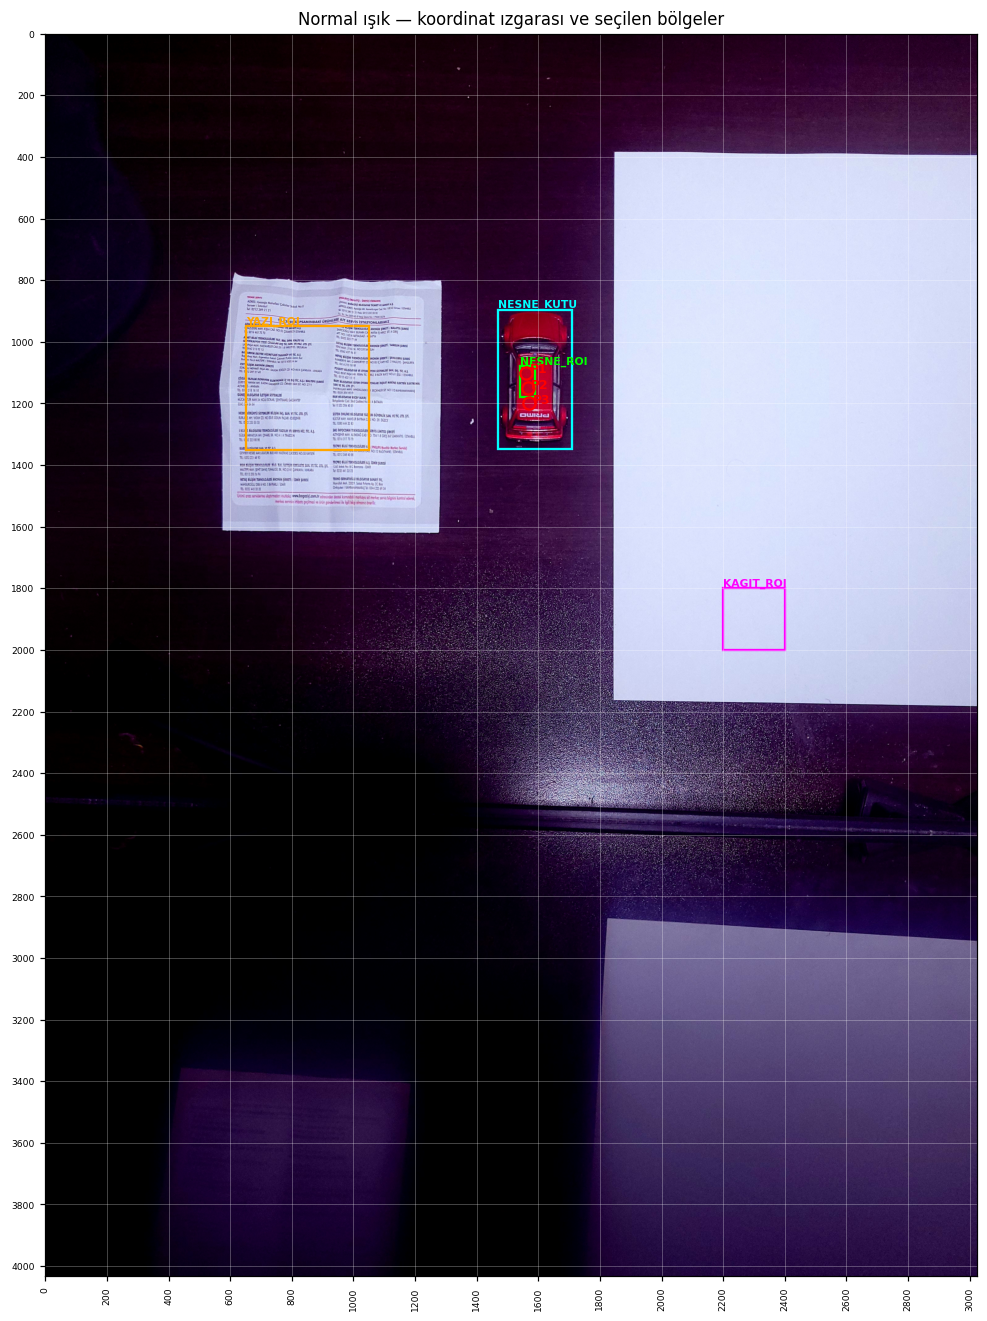

In [55]:
def izgara_ciz(rgb, baslik):
    H, W = rgb.shape[:2]
    fig, ax = plt.subplots(figsize=(11, 11 * H / W))
    ax.imshow(rgb)
    adim = max(50, int(round(max(H, W) / 20 / 50)) * 50)
    ax.set_xticks(np.arange(0, W, adim)); ax.set_yticks(np.arange(0, H, adim))
    ax.tick_params(axis="x", labelrotation=90, labelsize=6); ax.tick_params(axis="y", labelsize=6)
    ax.grid(color="white", alpha=0.35, linewidth=0.5)
    renkler = {"NESNE_ROI": "lime", "NESNE_KUTU": "cyan", "KAGIT_ROI": "magenta", "YAZI_ROI": "orange"}
    for ad, roi in [("NESNE_ROI", NESNE_ROI), ("NESNE_KUTU", NESNE_KUTU), ("KAGIT_ROI", KAGIT_ROI), ("YAZI_ROI", YAZI_ROI)]:
        if roi is not None:
            x, y, w, h = roi
            ax.add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec=renkler[ad], lw=1.5))
            ax.text(x, y - 8, ad, color=renkler[ad], fontsize=7, weight="bold")
    for i, p in enumerate(PIKSELLER):
        if p is not None:
            ax.plot(*p, "o", mfc="none", mec="red", ms=8, mew=1.5)
            ax.text(p[0] + 12, p[1], f"P{i+1}", color="red", fontsize=8, weight="bold")
    ax.set_title(baslik)
    return fig

fig = izgara_ciz(RGB["normal"], "Normal ışık — koordinat ızgarası ve seçilen bölgeler")
kaydet(fig, "izgara_normal.png"); plt.show()

for ad, deger in [("PIKSELLER", PIKSELLER), ("NESNE_ROI", NESNE_ROI), ("KAGIT_ROI", KAGIT_ROI), ("YAZI_ROI", YAZI_ROI)]:
    kontrol_dolu(ad, deger)
H_img, W_img = BGR["normal"].shape[:2]
for ad, roi in [("NESNE_ROI", NESNE_ROI), ("NESNE_KUTU", NESNE_KUTU), ("KAGIT_ROI", KAGIT_ROI), ("YAZI_ROI", YAZI_ROI)]:
    if roi is not None:
        x, y, w, h = roi
        assert 0 <= x and 0 <= y and x + w <= W_img and y + h <= H_img, f"{ad} görüntü dışına taşıyor: {roi}"
for p in PIKSELLER:
    assert 0 <= p[0] < W_img and 0 <= p[1] < H_img, f"Piksel görüntü dışında: {p}"

In [57]:
def yakin_plan(x0, x1, y0, y1, ana=50, ince=10, baslik=""):
    fig, ax = plt.subplots(figsize=(9, 9 * (y1 - y0) / (x1 - x0)))
    ax.imshow(RGB["normal"][y0:y1, x0:x1], extent=(x0, x1, y1, y0), interpolation="nearest")
    ax.set_xticks(np.arange(x0, x1, ana)); ax.set_yticks(np.arange(y0, y1, ana))
    ax.set_xticks(np.arange(x0, x1, ince), minor=True); ax.set_yticks(np.arange(y0, y1, ince), minor=True)
    ax.grid(which="major", color="white", alpha=0.6, lw=0.6)
    ax.grid(which="minor", color="white", alpha=0.15, lw=0.3)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(baslik); plt.show()

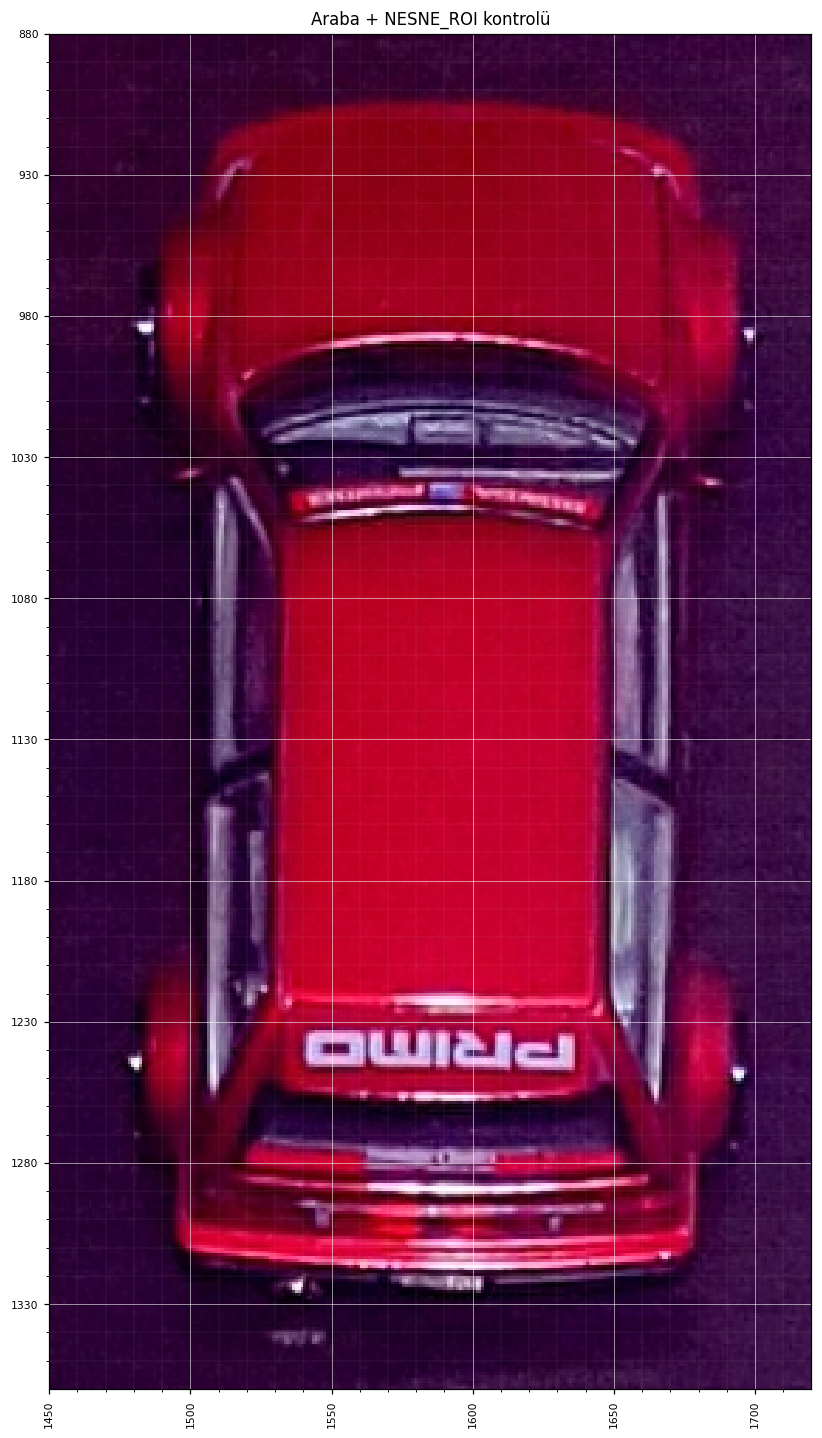

In [ ]:
yakin_plan(1450, 1720, 880, 1360, baslik="Araba + NESNE_ROI kontrolü")

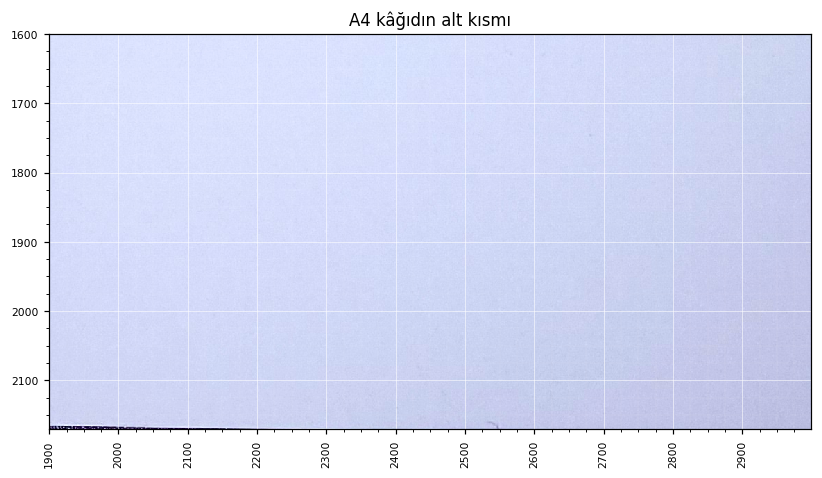

In [59]:
yakin_plan(1900, 3000, 1600, 2170, ana=100, ince=25, baslik="A4 kâğıdın alt kısmı")

In [60]:
k = kes(RGB["normal"], KAGIT_ROI)
print("ortalama R,G,B:", k.reshape(-1, 3).mean(0).round(1),
      "| 255'e dayanan piksel: %", round(100 * (k == 255).any(2).mean(), 1))

ortalama R,G,B: [211.7 218.1 249.7] | 255'e dayanan piksel: % 2.3


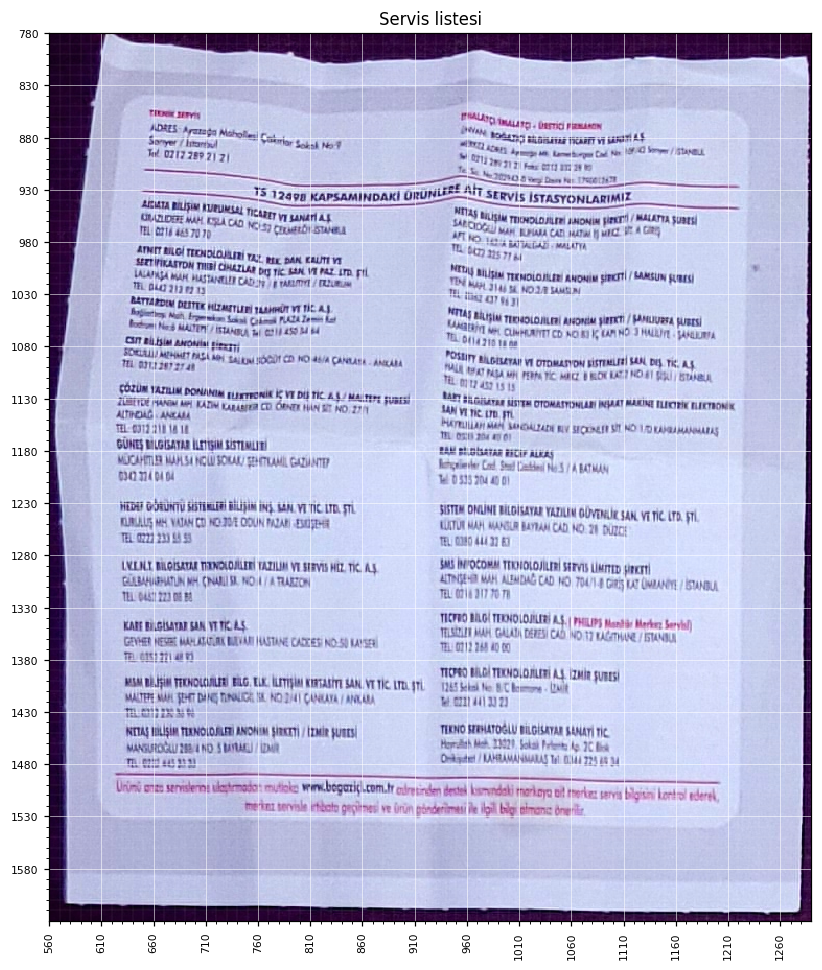

In [61]:
yakin_plan(560, 1290, 780, 1630, ana=50, ince=10, baslik="Servis listesi")

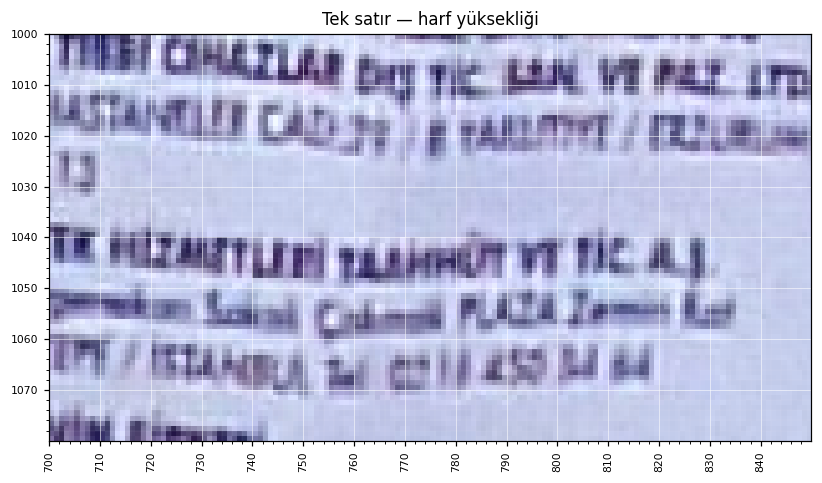

In [62]:
yakin_plan(700, 850, 1000, 1080, ana=10, ince=2, baslik="Tek satır — harf yüksekliği")

### 1.3 `img[y, x, kanal]` erişimi ve BGR → RGB
NumPy dizisi önce **satır (y)**, sonra **sütun (x)** ile indekslenir. OpenCV kanal sırası **B, G, R**'dir.

img.shape = (4032, 3024, 3)  →  (H, W, C)
img[1100, 1560]        (OpenCV, BGR) = (38, 0, 191)
img[1100, 1560, 2]     (R kanalı)     = 191
rgb[1100, 1560]        (dönüşüm sonrası RGB) = (191, 0, 38)
rgb == bgr[..., ::-1]  →  doğrulandı
YANLIŞ erişim img[1560, 1100] (x, y ters) = (234, 200, 194)  ← başka bir piksel
kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/bgr_rgb.png


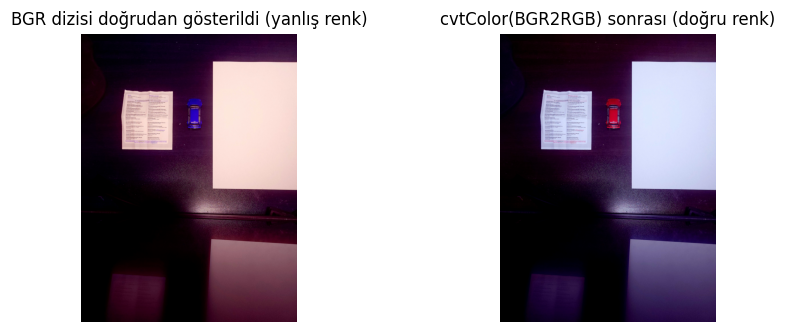

In [63]:
x0, y0 = PIKSELLER[0]
im = BGR["normal"]
print(f"img.shape = {im.shape}  →  (H, W, C)")
print(f"img[{y0}, {x0}]        (OpenCV, BGR) = {tuple(int(v) for v in im[y0, x0])}")
print(f"img[{y0}, {x0}, 2]     (R kanalı)     = {int(im[y0, x0, 2])}")
rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
print(f"rgb[{y0}, {x0}]        (dönüşüm sonrası RGB) = {tuple(int(v) for v in rgb[y0, x0])}")
assert np.array_equal(rgb[..., ::-1], im), "BGR→RGB kanal sırasını tersine çevirmekle aynı olmalı"
print("rgb == bgr[..., ::-1]  →  doğrulandı")
if y0 != x0 and x0 < im.shape[0] and y0 < im.shape[1]:
    print(f"YANLIŞ erişim img[{x0}, {y0}] (x, y ters) = {tuple(int(v) for v in im[x0, y0])}  ← başka bir piksel")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].imshow(im); axs[0].set_title("BGR dizisi doğrudan gösterildi (yanlış renk)")
axs[1].imshow(rgb); axs[1].set_title("cvtColor(BGR2RGB) sonrası (doğru renk)")
for a in axs: a.axis("off")
kaydet(fig, "bgr_rgb.png"); plt.show()

### 1.4 Aynı fiziksel noktaların üç ışıktaki değerleri
Tek piksel değerine ek olarak gürültüyü azaltmak için 5×5 komşuluk ortalaması da verilir. Kâğıt bölgesinin ortalaması ışığın rengini (ve beyaz dengesini) gösterir.

In [64]:
def komsu_ort(rgb, x, y, r=2):
    return rgb[max(0, y - r):y + r + 1, max(0, x - r):x + r + 1].reshape(-1, 3).mean(0)

piksel_satirlari = []
for i, (x, y) in enumerate(PIKSELLER):
    for ad in DOSYALAR:
        r, g, b = (int(v) for v in RGB[ad][y, x])
        mr, mg, mb = komsu_ort(RGB[ad], x, y)
        h, s, v = (int(t) for t in HSV[ad][y, x])
        piksel_satirlari.append({"nokta": f"P{i+1}", "x": x, "y": y, "fotograf": ad, "R": r, "G": g, "B": b,
                                 "R_5x5": round(mr, 1), "G_5x5": round(mg, 1), "B_5x5": round(mb, 1),
                                 "H": h, "S": s, "V": v})
piksel_df = pd.DataFrame(piksel_satirlari)
piksel_df.to_csv(CIKTI / "piksel_degerleri.csv", index=False)
print(piksel_df.to_string(index=False))

kagit_satirlari = []
for ad in DOSYALAR:
    m = kes(RGB[ad], KAGIT_ROI).reshape(-1, 3).astype(np.float64).mean(0)
    kagit_satirlari.append({"fotograf": ad, "R": round(m[0], 1), "G": round(m[1], 1), "B": round(m[2], 1),
                            "R/G": round(m[0] / m[1], 3), "B/G": round(m[2] / m[1], 3),
                            "parlaklik_orani_normale_gore": None})
kagit_df = pd.DataFrame(kagit_satirlari)
g_norm = kagit_df.loc[kagit_df.fotograf == "normal", ["R", "G", "B"]].values.mean()
kagit_df["parlaklik_orani_normale_gore"] = (kagit_df[["R", "G", "B"]].mean(1) / g_norm).round(3)
kagit_df.to_csv(CIKTI / "kagit_isik_rengi.csv", index=False)
print("\nKâğıt bölgesi (ışığın rengi): R/G > 1 sıcak, B/G > 1 soğuk ışık")
print(kagit_df.to_string(index=False))

nokta    x    y fotograf   R  G  B  R_5x5  G_5x5  B_5x5   H   S   V
   P1 1560 1100   normal 191  0 38  190.8    0.5   37.8 174 255 191
   P1 1560 1100    golge  99  0  1  100.4    0.2    2.0   0 255  99
   P1 1560 1100    lamba 189  0  0  189.3    0.2    0.7   0 255 189
   P2 1565 1150   normal 193  1 40  192.6    0.7   37.6 174 254 193
   P2 1565 1150    golge 108  0  0  108.3    0.3    0.4   0 255 108
   P2 1565 1150    lamba 199  1  0  199.0    0.5    0.1   0 255 199
   P3 1570 1200   normal 203  0 47  201.0    0.4   43.9 173 255 203
   P3 1570 1200    golge 118  0  0  118.5    0.4    1.0   0 255 118
   P3 1570 1200    lamba 219  0  0  217.9    0.3    0.6   0 255 219

Kâğıt bölgesi (ışığın rengi): R/G > 1 sıcak, B/G > 1 soğuk ışık
fotograf     R     G     B   R/G   B/G  parlaklik_orani_normale_gore
  normal 211.7 218.1 249.7 0.971 1.145                         1.000
   golge 170.2 169.6 208.3 1.003 1.228                         0.807
   lamba 206.2 104.8  69.9 1.967 0.667          

## 2. Sabit renk eşikleri (Hedef 2 — Deney 5)
### 2.1 Eşikleri yalnızca normal ışıkta belirle ve dondur

In [65]:
tahmin_kontrol("D5_renk_esikleri")

def ton_araligi(h, yuzdelik, pay):
    """Ton dairesel (0–179). Kırmızı gibi 0/179 sınırını aşan tonlar için kaydırarak hesaplar; alt > üst ise aralık sarar."""
    sarar = (np.mean(h < 20) > 0.2) and (np.mean(h > 160) > 0.2)
    if sarar:
        hk = (h.astype(int) + 90) % 180
        lo, hi = np.percentile(hk, yuzdelik)
        return (int((lo - pay - 90) % 180), int((hi + pay - 90) % 180))
    lo, hi = np.percentile(h, yuzdelik)
    return (int(max(0, lo - pay)), int(min(179, hi + pay)))

def oneri_hesapla():
    rgb_roi = kes(RGB["normal"], NESNE_ROI).reshape(-1, 3)
    hsv_roi = kes(HSV["normal"], NESNE_ROI).reshape(-1, 3)
    p_lo, p_hi = ESIK_YUZDELIK
    rgb_e = {}
    for i, k in enumerate("RGB"):
        lo, hi = np.percentile(rgb_roi[:, i], [p_lo, p_hi])
        if np.median(rgb_roi[:, i]) >= 128:          # parlak kanal → "k > alt"
            rgb_e[k] = (int(max(0, lo - ESIK_PAY)), 255)
        else:                                         # koyu kanal → "k < üst"
            rgb_e[k] = (0, int(min(255, hi + ESIK_PAY)))
    s_lo = np.percentile(hsv_roi[:, 1], p_lo)
    hsv_e = {"H": ton_araligi(hsv_roi[:, 0], ESIK_YUZDELIK, ESIK_PAY_H),
             "S": (int(max(0, s_lo - ESIK_PAY)), 255),
             "V": (int(ESIK_V_ALT), 255)}
    return rgb_e, hsv_e

oneri_rgb, oneri_hsv = oneri_hesapla()
ESIK_RGB_SABIT = ESIK_RGB if ESIK_RGB is not None else oneri_rgb
ESIK_HSV_SABIT = ESIK_HSV if ESIK_HSV is not None else oneri_hsv
kaynak = "elle (0.1)" if ESIK_RGB is not None else "normal fotoğraftaki NESNE_ROI yüzdeliklerinden otomatik"
print("Eşik kaynağı:", kaynak)
print("DONDURULDU  RGB:", ESIK_RGB_SABIT)
print("DONDURULDU  HSV:", ESIK_HSV_SABIT, "(OpenCV 8 bit: H 0–179)")
print("\n0.1'e kopyalamak için:")
print("ESIK_RGB =", ESIK_RGB_SABIT)
print("ESIK_HSV =", ESIK_HSV_SABIT)
esik_imzasi = hashlib.md5(json.dumps([ESIK_RGB_SABIT, ESIK_HSV_SABIT], sort_keys=True).encode()).hexdigest()[:8]
print("Eşik imzası (her maskede aynı olmalı):", esik_imzasi)

[TAHMİN D5_renk_esikleri] Gölgede üç kanal birlikte düşeceği için arabanın R değeri sabit RGB eşiğinin alt sınırının altına inecek ve RGB maskesi büyük ölçüde boşalacak.
                            HSV uzayında kırmızı renk 0/179 ton (Hue) sınırında ikiye bölündüğü için tek bir dar aralık kullanılırsa normalde bile piksellerin bir kısmı kaçabilir;
                            gölgede parlaklık düşse de ton korunduğu için HSV maskesi RGB'ye göre daha az küçülecek. Ancak lambanın ışığı nesneyle aynı tonda olduğundan,
                            lamba altında beyaz kağıt ve masa yansıması da kırmızı/turuncu tona kayıp HSV eşiğine girecek; bu yüzden lamba altında HSV maskesi küçülmek yerine
                            arka planı da kapsayarak büyüyecek veya yüksek doygunlukla arabanın tamamını tutmaya devam edecek.
Eşik kaynağı: normal fotoğraftaki NESNE_ROI yüzdeliklerinden otomatik
DONDURULDU  RGB: {'R': (168, 255), 'G': (0, 13), 'B': (0, 55)}
DONDURULDU  HSV: {'H': (169, 179), 'S': (241,

### 2.2 Aynı eşikleri üç fotoğrafa uygula — 6 maske
Alan oranı = seçilen piksel / görüntü alanı. **Bu bir doğruluk ölçütü değildir**; yalnızca maskenin ne kadar büyüdüğünü/küçüldüğünü gösterir. Nesne kutusu verilmişse kutu dışında seçilen pikseller ayrıca sayılır (ör. sarımsı masa yüzeyi).

fotograf yontem  secilen_piksel  alan_orani_%  nesne_roi_icinde_secilen_%  kutu_disinda_secilen_piksel  secilenlerin_kutu_disi_payi_%
  normal    RGB           17697         0.145                       100.0                            0                            0.0
  normal    HSV           41156         0.338                       100.0                            0                            0.0
   golge    RGB             306         0.003                         0.0                            0                            0.0
   golge    HSV           10876         0.089                         9.8                            0                            0.0
   lamba    RGB           16798         0.138                        98.8                           32                            0.2
   lamba    HSV          180221         1.478                         0.1                       175860                           97.6
kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Orne

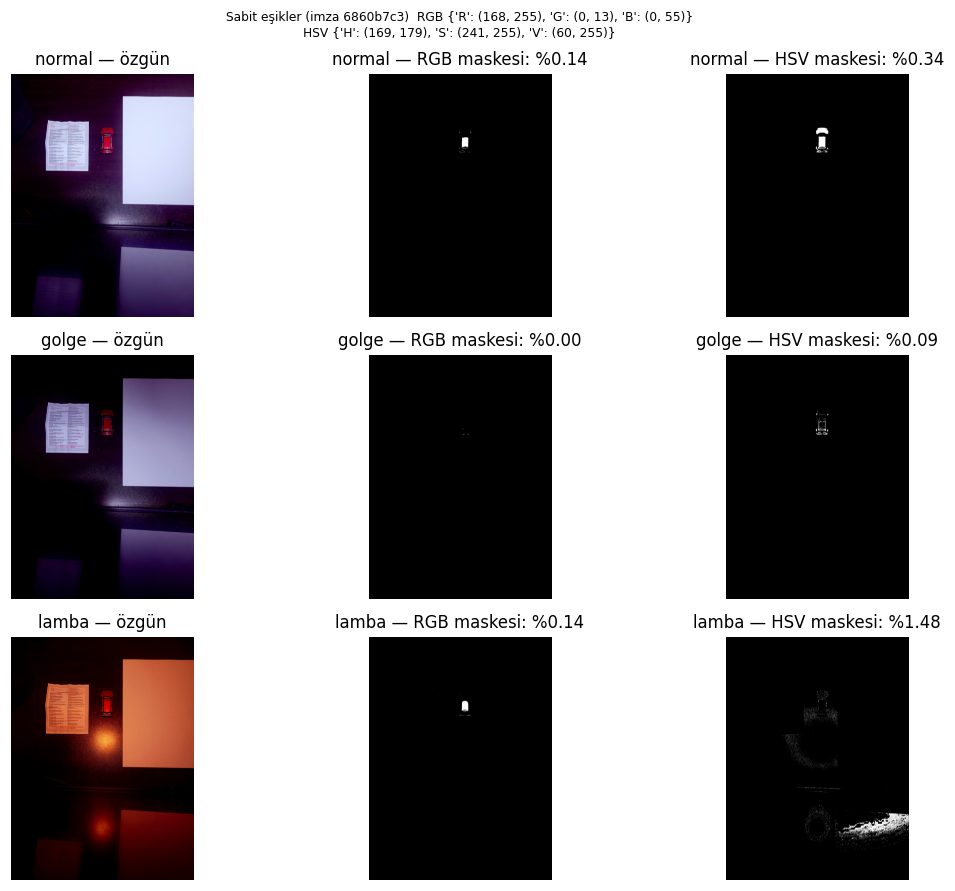

In [66]:
def rgb_maske(rgb, e):
    lo = np.array([e["R"][0], e["G"][0], e["B"][0]], np.uint8)
    hi = np.array([e["R"][1], e["G"][1], e["B"][1]], np.uint8)
    return cv2.inRange(rgb, lo, hi)

def hsv_maske(hsv, e):
    (h0, h1), (s0, s1), (v0, v1) = e["H"], e["S"], e["V"]
    if h0 <= h1:
        return cv2.inRange(hsv, np.array([h0, s0, v0], np.uint8), np.array([h1, s1, v1], np.uint8))
    m1 = cv2.inRange(hsv, np.array([h0, s0, v0], np.uint8), np.array([179, s1, v1], np.uint8))
    m2 = cv2.inRange(hsv, np.array([0, s0, v0], np.uint8), np.array([h1, s1, v1], np.uint8))
    return cv2.bitwise_or(m1, m2)

MASKE = {}
for ad in DOSYALAR:
    MASKE[(ad, "RGB")] = rgb_maske(RGB[ad], ESIK_RGB_SABIT)
    MASKE[(ad, "HSV")] = hsv_maske(HSV[ad], ESIK_HSV_SABIT)

kutu_ici = None
if NESNE_KUTU is not None:
    kutu_ici = np.zeros(BGR["normal"].shape[:2], bool)
    x, y, w, h = NESNE_KUTU
    kutu_ici[y:y + h, x:x + w] = True

alan = H_img * W_img
maske_satirlari = []
for (ad, yontem), m in MASKE.items():
    sec = m > 0
    satir = {"fotograf": ad, "yontem": yontem, "secilen_piksel": int(sec.sum()),
             "alan_orani_%": round(100 * sec.sum() / alan, 3),
             "nesne_roi_icinde_secilen_%": round(100 * (kes(m, NESNE_ROI) > 0).mean(), 1)}
    if kutu_ici is not None:
        satir["kutu_disinda_secilen_piksel"] = int((sec & ~kutu_ici).sum())
        satir["secilenlerin_kutu_disi_payi_%"] = round(100 * (sec & ~kutu_ici).sum() / max(1, sec.sum()), 1)
    cv2.imwrite(str(CIKTI / f"maske_{ad}_{yontem}.png"), m)
    maske_satirlari.append(satir)
maske_df = pd.DataFrame(maske_satirlari)
maske_df.to_csv(CIKTI / "maske_oranlari.csv", index=False)
print(maske_df.to_string(index=False))

fig, axs = plt.subplots(3, 3, figsize=(11, 8.2))
for i, ad in enumerate(DOSYALAR):
    axs[i, 0].imshow(RGB[ad]); axs[i, 0].set_title(f"{ad} — özgün")
    for j, yontem in enumerate(["RGB", "HSV"]):
        oran = maske_df.query("fotograf == @ad and yontem == @yontem")["alan_orani_%"].item()
        axs[i, j + 1].imshow(MASKE[(ad, yontem)], cmap="gray", vmin=0, vmax=255)
        axs[i, j + 1].set_title(f"{ad} — {yontem} maskesi: %{oran:.2f}")
    for a in axs[i]: a.axis("off")
fig.suptitle(f"Sabit eşikler (imza {esik_imzasi})  RGB {ESIK_RGB_SABIT}\nHSV {ESIK_HSV_SABIT}", fontsize=8)
fig.tight_layout()
kaydet(fig, "maskeler_3x3.png"); plt.show()

### 2.3 Neden seçildi / neden kaçtı? — nesne bölgesinin renk değerleri ve nesne dışı seçimler
Kırmızı katman: maskenin seçtiği ama nesne kutusunun **dışında** kalan pikseller. "Sarı bir arka plan neden hedef gibi seçildi?" sorusunu bu görselle yanıtlayın.

NESNE_ROI ortalamaları (aynı fiziksel bölge):
fotograf     R   G    B  H_medyan  S_ort  V_ort
  normal 191.5 0.7 37.9     174.0  254.2  191.5
   golge 105.9 0.3  0.7       0.0  254.5  105.9
   lamba 194.2 0.5  0.8       0.0  254.6  194.2
Eşik aralıkları  RGB: {'R': (168, 255), 'G': (0, 13), 'B': (0, 55)}  HSV: {'H': (169, 179), 'S': (241, 255), 'V': (60, 255)}
kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/nesne_disi_secim.png


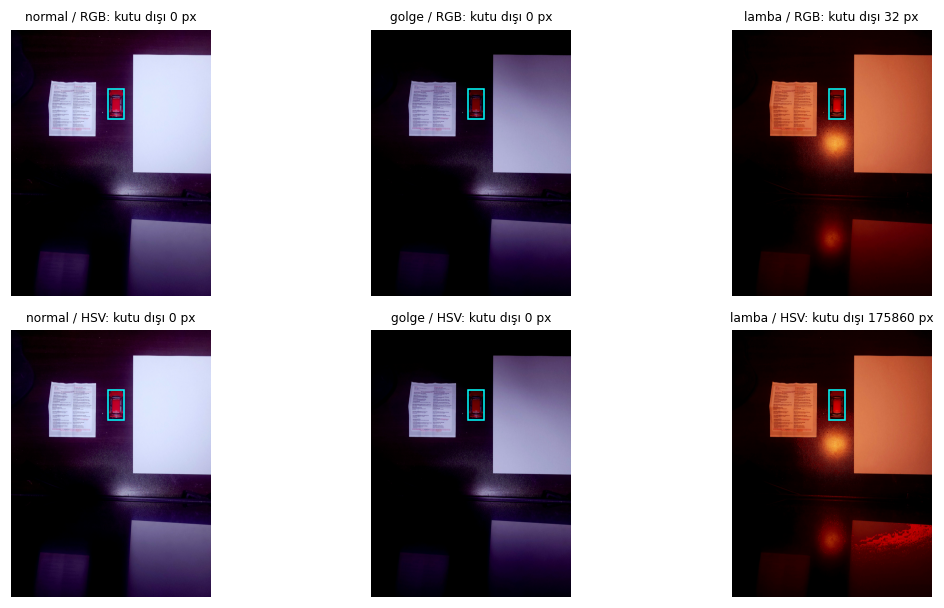

In [67]:
roi_satirlari = []
for ad in DOSYALAR:
    r = kes(RGB[ad], NESNE_ROI).reshape(-1, 3).astype(float).mean(0)
    h = kes(HSV[ad], NESNE_ROI).reshape(-1, 3).astype(float)
    roi_satirlari.append({"fotograf": ad, "R": round(r[0], 1), "G": round(r[1], 1), "B": round(r[2], 1),
                          "H_medyan": float(np.median(h[:, 0])), "S_ort": round(h[:, 1].mean(), 1),
                          "V_ort": round(h[:, 2].mean(), 1)})
roi_df = pd.DataFrame(roi_satirlari)
roi_df.to_csv(CIKTI / "nesne_roi_renk.csv", index=False)
print("NESNE_ROI ortalamaları (aynı fiziksel bölge):")
print(roi_df.to_string(index=False))
print("Eşik aralıkları  RGB:", ESIK_RGB_SABIT, " HSV:", ESIK_HSV_SABIT)

if kutu_ici is not None:
    fig, axs = plt.subplots(2, 3, figsize=(11, 5.6))
    for j, ad in enumerate(DOSYALAR):
        for i, yontem in enumerate(["RGB", "HSV"]):
            gor = RGB[ad].copy()
            dis = (MASKE[(ad, yontem)] > 0) & ~kutu_ici
            gor[dis] = (0.35 * gor[dis] + 0.65 * np.array([255, 0, 0])).astype(np.uint8)
            x, y, w, h = NESNE_KUTU
            axs[i, j].imshow(gor)
            axs[i, j].add_patch(mpatches.Rectangle((x, y), w, h, fill=False, ec="cyan", lw=1))
            axs[i, j].set_title(f"{ad} / {yontem}: kutu dışı {int(dis.sum())} px", fontsize=8)
            axs[i, j].axis("off")
    fig.tight_layout(); kaydet(fig, "nesne_disi_secim.png"); plt.show()
else:
    print("NESNE_KUTU verilmedi: nesne dışı seçim görseli atlandı.")

## 3. Parlaklık kaydırması ve gama (Hedef 3 — Deney 6)
İşlemler float32 üzerinde yapılır, sonuç [0, 255]'e kırpılır. Ölçüm float sonuç üzerindedir; gösterim/kayıt için yuvarlanıp uint8'e çevrilir.

In [68]:
tahmin_kontrol("D6a_parlaklik_b40", "D6b_gama_0_5", "D6c_gama_2_0")

def parlaklik_kaydir(I, b):
    """J = clip(I + b, 0, 255)"""
    return np.clip(I.astype(np.float32) + b, 0, 255)

def gama_donusumu(I, gama):
    """J = 255 · (I / 255)^γ  — γ formüldeki üstür."""
    return np.clip(255.0 * (I.astype(np.float32) / 255.0) ** gama, 0, 255)

def uint8(J):
    return np.round(J).astype(np.uint8)

for v in [64, 128, 200]:
    print(f"I={v:3d}:  γ=0.5 → {gama_donusumu(np.array([v]), 0.5)[0]:6.1f}   "
          f"γ=2.0 → {gama_donusumu(np.array([v]), 2.0)[0]:6.1f}   b=+40 → {parlaklik_kaydir(np.array([v]), 40)[0]:6.1f}")

I = RGB["normal"]
If = I.astype(np.float64)
ort0 = If.mean()
DONUSUM = {f"b=+{PARLAKLIK_B}": parlaklik_kaydir(I, PARLAKLIK_B)}
for g in GAMALAR:
    DONUSUM[f"γ={g}"] = gama_donusumu(I, g)

tahmin_anahtari = {f"b=+{PARLAKLIK_B}": "ortalama_degisim_b40", "γ=0.5": "ortalama_degisim_gama_0_5",
                   "γ=2.0": "ortalama_degisim_gama_2_0"}
donusum_satirlari = []
for ad, J in DONUSUM.items():
    ort = float(J.astype(np.float64).mean())
    satir = {"donusum": ad, "ozgun_ortalama": round(ort0, 2), "olculen_ortalama": round(ort, 2),
             "olculen_degisim": round(ort - ort0, 2),
             "tahmin_degisim": TAHMIN_SAYISAL.get(tahmin_anahtari.get(ad, ""), None)}
    if ad.startswith("b="):
        kirpilan = (If + PARLAKLIK_B) > 255
        satir["kirpmasiz_beklenen"] = round(ort0 + PARLAKLIK_B, 2)
        satir["kirpilan_kanal_degeri_%"] = round(100 * kirpilan.mean(), 2)
        satir["kirpilan_piksel_(herhangi_kanal)_%"] = round(100 * kirpilan.any(axis=2).mean(), 2)
        kayip = np.maximum(If + PARLAKLIK_B - 255, 0).mean()
        satir["kirpma_kaybi"] = round(kayip, 2)
        assert abs((ort0 + PARLAKLIK_B - kayip) - ort) < 1e-3, "kırpma açıklaması ölçümle tutmalı"
    else:
        g = float(ad.split("=")[1])
        satir["ortalamanin_gamasi_255(m/255)^γ"] = round(255 * (ort0 / 255) ** g, 2)
    donusum_satirlari.append(satir)
    cv2.imwrite(str(CIKTI / f"donusum_{ad.replace('=', '').replace('+', 'p').replace('γ', 'gama')}.png"),
                cv2.cvtColor(uint8(J), cv2.COLOR_RGB2BGR))
donusum_df = pd.DataFrame(donusum_satirlari)
donusum_df.to_csv(CIKTI / "donusum_olcumleri.csv", index=False)
print(donusum_df.T.to_string(header=False))
print("\nNot: γ dönüşümünde ortalamanın gaması ≠ gamanın ortalaması (dışbükey/içbükey fonksiyon, Jensen eşitsizliği).")

[TAHMİN D6a_parlaklik_b40] b = +40: “Ortalama 71'den 111'e çıkmalı; görüntünün büyük kısmı koyu masa yüzeyi olduğu için kırpılma az olacak,
                            sadece sağdaki beyaz kağıdın 255'e yakın pikselleri kırpılacağı için artış 40'ın biraz altında, yaklaşık +37 olacak (ölçülen yeni ortalama ≈ 108).
[TAHMİN D6b_gama_0_5] γ = 0,5: “Formüle göre 255 * (71/255)^{0,5} = 134 olduğu için ortalamanın yaklaşık +63 artmasını bekleriz;
                            ancak görüntünün çoğu çok koyu piksellerden ve bir kısmı parlak beyaz kağıttan oluştuğu için iki uçtaki pikseller orta tonlar
                            kadar artmayacak ve gerçek ortalama artışı daha düşük çıkacak.
[TAHMİN D6c_gama_2_0] γ = 2,0: “Formüle göre 255 * (71/255)^2 = 20 olduğu için ortalamanın yaklaşık −51 düşmesi beklenir;
                            fakat ortalamanın gaması ile gamanın ortalaması aynı şey olmadığından ve görüntünün %60'ı zaten 0'a çok yakın koyu piksellerden oluşup
                          

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/parlaklik_gama.png


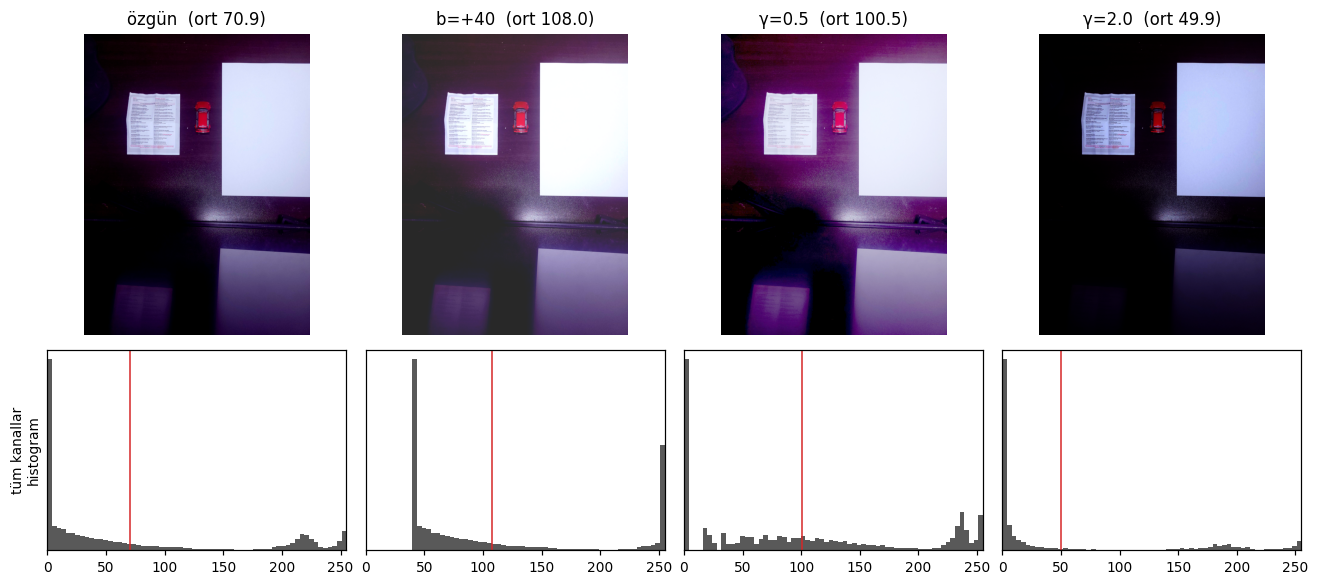

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/kirpilan_pikseller.png


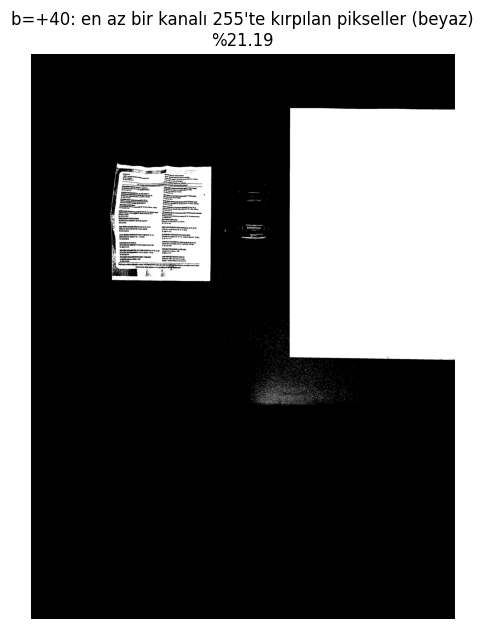

In [69]:
fig, axs = plt.subplots(2, 4, figsize=(12, 5.4), gridspec_kw={"height_ratios": [3, 2]})
paneller = [("özgün", I.astype(np.float32))] + list(DONUSUM.items())
for j, (ad, J) in enumerate(paneller):
    axs[0, j].imshow(uint8(J)); axs[0, j].axis("off")
    axs[0, j].set_title(f"{ad}  (ort {J.mean():.1f})")
    axs[1, j].hist(J.ravel(), bins=64, range=(0, 255), color="0.35")
    axs[1, j].axvline(J.mean(), color="tab:red", lw=1)
    axs[1, j].set_xlim(0, 255); axs[1, j].set_yticks([])
axs[1, 0].set_ylabel("tüm kanallar\nhistogram")
fig.tight_layout(); kaydet(fig, "parlaklik_gama.png"); plt.show()

kirp = ((If + PARLAKLIK_B) > 255).any(axis=2)
fig, ax = plt.subplots(figsize=(5, 5 * H_img / W_img))
ax.imshow(kirp, cmap="gray"); ax.axis("off")
ax.set_title(f"b=+{PARLAKLIK_B}: en az bir kanalı 255'te kırpılan pikseller (beyaz)\n%{100 * kirp.mean():.2f}")
kaydet(fig, "kirpilan_pikseller.png"); plt.show()

## 4. Küçültmenin etkisi (Hedef 4 — Deney 7)
Yazı bölgesi genişlik ve yükseklikte 1/4'e küçültülür (`INTER_NEAREST` ve `INTER_AREA`). Yalnızca gösterim için en yakın komşuyla özgün boyuta büyütülür. Ek panel: daha "akıllı" bir büyütme (`INTER_CUBIC`) bile kaybolan bilgiyi geri getirmez.

In [70]:
tahmin_kontrol("D7_kucultme")

yazi = kes(RGB["normal"], YAZI_ROI)
hh, ww = (yazi.shape[0] // OLCEK) * OLCEK, (yazi.shape[1] // OLCEK) * OLCEK
yazi = yazi[:hh, :ww]                       # 4'ün katına kırp: büyütme sonrası boyut birebir eşleşsin
kucuk = (ww // OLCEK, hh // OLCEK)          # cv2.resize boyutu (genişlik, yükseklik) ister
K = {"nearest": cv2.resize(yazi, kucuk, interpolation=cv2.INTER_NEAREST),
     "area":    cv2.resize(yazi, kucuk, interpolation=cv2.INTER_AREA)}
B = {k: cv2.resize(v, (ww, hh), interpolation=cv2.INTER_NEAREST) for k, v in K.items()}
B["area+cubic"] = cv2.resize(K["area"], (ww, hh), interpolation=cv2.INTER_CUBIC)
for k, v in K.items():
    cv2.imwrite(str(CIKTI / f"kucuk_{k}.png"), cv2.cvtColor(v, cv2.COLOR_RGB2BGR))

def gri(x): return cv2.cvtColor(x, cv2.COLOR_RGB2GRAY).astype(np.float64)
def kenar_enerjisi(x):
    g = gri(x); return float(np.mean(np.abs(np.diff(g, axis=1))) + np.mean(np.abs(np.diff(g, axis=0))))

kucultme_satirlari = [{"goruntu": "özgün kesit", "boyut": f"{ww}x{hh}", "MAE_ozgune": 0.0,
                       "kontrast_std": round(gri(yazi).std(), 2), "kenar_enerjisi": round(kenar_enerjisi(yazi), 2)}]
for k, v in B.items():
    kucultme_satirlari.append({"goruntu": f"{k} (1/{OLCEK} → özgün boyut)",
                               "boyut": f"{K['area' if 'area' in k else k].shape[1]}x{K['area' if 'area' in k else k].shape[0]} → {ww}x{hh}",
                               "MAE_ozgune": round(float(np.abs(gri(v) - gri(yazi)).mean()), 2),
                               "kontrast_std": round(gri(v).std(), 2), "kenar_enerjisi": round(kenar_enerjisi(v), 2)})
kucultme_df = pd.DataFrame(kucultme_satirlari)
kucultme_df.to_csv(CIKTI / "kucultme_olcumleri.csv", index=False)
print(kucultme_df.to_string(index=False))
if YAZI_HARF_YUKSEKLIGI_PX:
    print(f"\nHarf yüksekliği: {YAZI_HARF_YUKSEKLIGI_PX} px → 1/{OLCEK} küçültmede ≈ {YAZI_HARF_YUKSEKLIGI_PX / OLCEK:.1f} px")
print("MAE: özgün kesite ortalama mutlak fark (gri, 0–255). Kenar enerjisi: komşu pikseller arası ortalama mutlak fark.")

[TAHMİN D7_kucultme] Fişteki küçük harfler yaklaşık 6–8 piksel yüksekliğinde; 1/4 küçültmede 1,5–2 piksele inip tamamen okunamaz olacak.
                            NEAREST harflerin ince çizgilerini koparıp kesik noktalara çevirecek, AREA ise komşu piksellerin ortalamasını alarak
                            satırları bulanık gri şeritlere dönüştürecek. Tekrar büyütme iki durumda da harfleri geri getirmeyecek,
                            çünkü her 16 pikselin yerinde artık tek bir değer kaldı.
                       goruntu             boyut  MAE_ozgune  kontrast_std  kenar_enerjisi
                   özgün kesit           400x400        0.00         36.68           24.01
   nearest (1/4 → özgün boyut) 100x100 → 400x400       19.00         35.96           10.98
      area (1/4 → özgün boyut) 100x100 → 400x400       13.90         28.08            7.43
area+cubic (1/4 → özgün boyut) 100x100 → 400x400       13.27         26.91            8.10

Harf yüksekliği: 8 px → 1/4 küçültmede ≈ 2.0 

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/kucultme_karsilastirma.png


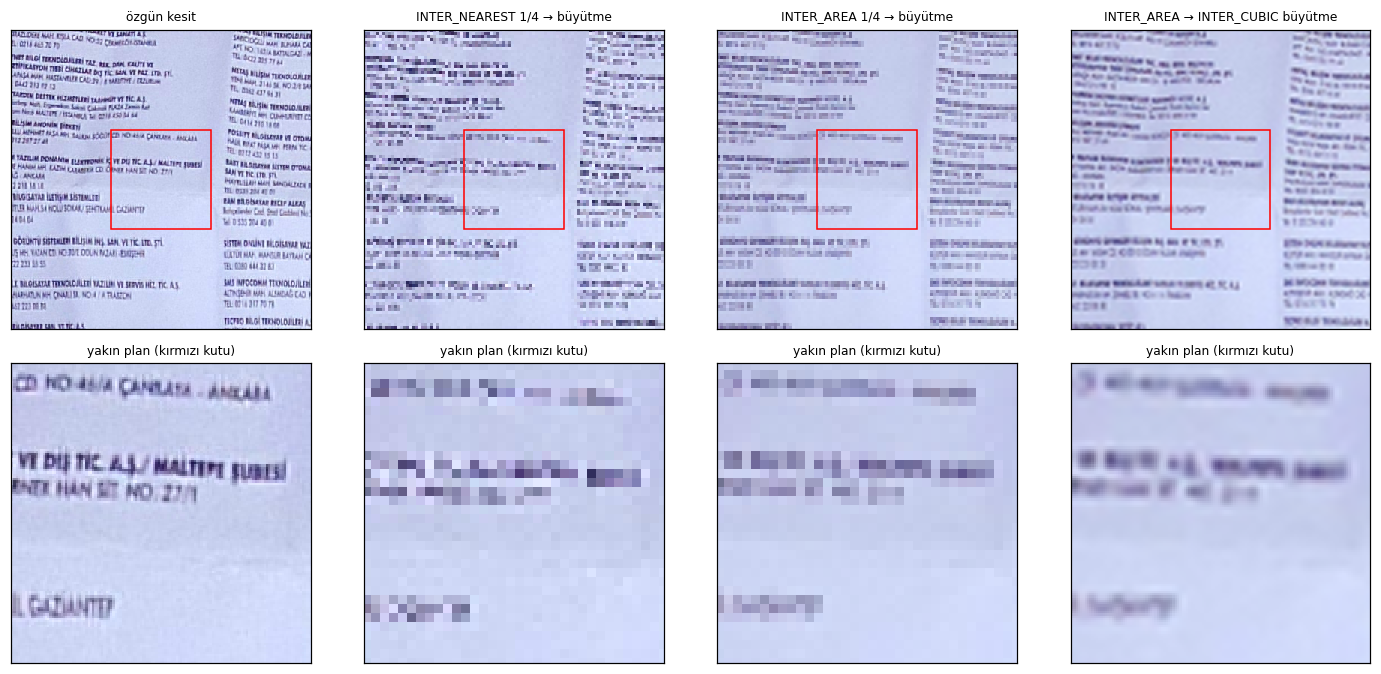

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/kucultme_gercek_pikseller.png


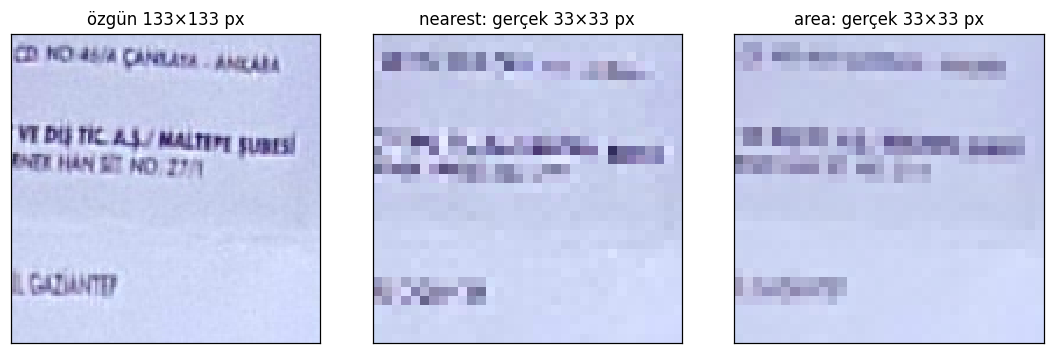

In [71]:
fig, axs = plt.subplots(2, 4, figsize=(13, 6.2))
paneller = [("özgün kesit", yazi), (f"INTER_NEAREST 1/{OLCEK} → büyütme", B["nearest"]),
            (f"INTER_AREA 1/{OLCEK} → büyütme", B["area"]), ("INTER_AREA → INTER_CUBIC büyütme", B["area+cubic"])]
zh, zw = max(16, hh // 3), max(16, ww // 3)                 # aynı küçük pencere (yakın plan)
zy, zx = (hh - zh) // 2, (ww - zw) // 2
for j, (ad, v) in enumerate(paneller):
    axs[0, j].imshow(v, interpolation="nearest"); axs[0, j].set_title(ad, fontsize=8)
    axs[0, j].add_patch(mpatches.Rectangle((zx, zy), zw, zh, fill=False, ec="red", lw=1))
    axs[1, j].imshow(v[zy:zy + zh, zx:zx + zw], interpolation="nearest")
    axs[1, j].set_title("yakın plan (kırmızı kutu)", fontsize=8)
    for a in axs[:, j]: a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); kaydet(fig, "kucultme_karsilastirma.png"); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(10, 3.2))
axs[0].imshow(yazi[zy:zy + zh, zx:zx + zw], interpolation="nearest"); axs[0].set_title(f"özgün {zw}×{zh} px")
axs[1].imshow(K["nearest"][zy // OLCEK:(zy + zh) // OLCEK, zx // OLCEK:(zx + zw) // OLCEK], interpolation="nearest")
axs[1].set_title(f"nearest: gerçek {zw // OLCEK}×{zh // OLCEK} px")
axs[2].imshow(K["area"][zy // OLCEK:(zy + zh) // OLCEK, zx // OLCEK:(zx + zw) // OLCEK], interpolation="nearest")
axs[2].set_title(f"area: gerçek {zw // OLCEK}×{zh // OLCEK} px")
for a in axs: a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); kaydet(fig, "kucultme_gercek_pikseller.png"); plt.show()

## 5. Sonuç tablosu: tahmin ↔ ölçüm
Raporda kullanılacak karşılaştırma tablosu. "tuttu_mu" sütunu yalnızca sayısal ve yön tahminleri için otomatik doldurulur; metin tahminlerini raporda kendiniz değerlendirin.

In [72]:
def oran(ad, yontem):
    return maske_df.query("fotograf == @ad and yontem == @yontem")["alan_orani_%"].item()

sonuc = []
for yontem in ["RGB", "HSV"]:
    for ad in ["golge", "lamba"]:
        olc = yon(oran(ad, yontem), oran("normal", yontem))
        t = TAHMIN_SAYISAL.get(f"{yontem.lower()}_oran_{ad}", "")
        sonuc.append({"deney": "D5 renk eşiği", "degisken": f"{yontem} maske alan oranı, normal → {ad}",
                      "tahmin": t or "—", "olcum": f"%{oran('normal', yontem):.2f} → %{oran(ad, yontem):.2f} ({olc})",
                      "tuttu_mu": ("evet" if t.strip() == olc else "hayır") if t else "—"})
for _, r in donusum_df.iterrows():
    t = r["tahmin_degisim"]
    tuttu = "—"
    if t is not None and not (isinstance(t, float) and np.isnan(t)):
        tuttu = "evet" if abs(float(t) - r["olculen_degisim"]) <= max(3.0, 0.1 * abs(r["olculen_degisim"])) else "hayır"
    sonuc.append({"deney": "D6 parlaklık/gama", "degisken": f"{r['donusum']} ortalama değişimi",
                  "tahmin": "—" if tuttu == "—" else f"{float(t):+.1f}",
                  "olcum": f"{r['olculen_degisim']:+.2f} ({r['ozgun_ortalama']} → {r['olculen_ortalama']})",
                  "tuttu_mu": tuttu})
for _, r in kucultme_df.iloc[1:].iterrows():
    sonuc.append({"deney": "D7 küçültme", "degisken": f"{r['goruntu']}: MAE / kontrast / kenar",
                  "tahmin": "metin (0.2)", "olcum": f"{r['MAE_ozgune']} / {r['kontrast_std']} / {r['kenar_enerjisi']}",
                  "tuttu_mu": "raporda"})
sonuc_df = pd.DataFrame(sonuc)
sonuc_df.to_csv(CIKTI / "sonuc_tablosu.csv", index=False)
print(sonuc_df.to_string(index=False))
tutmayan = sonuc_df[sonuc_df.tuttu_mu == "hayır"]
print(f"\nTutmayan tahmin sayısı: {len(tutmayan)}  (raporda en az birini 'Ne gördüm, neden olabilir, nasıl kontrol ederim?' ile açıklayın)")

            deney                                               degisken      tahmin                   olcum tuttu_mu
    D5 renk eşiği                   RGB maske alan oranı, normal → golge      azalır  %0.14 → %0.00 (azalır)     evet
    D5 renk eşiği                   RGB maske alan oranı, normal → lamba       artar    %0.14 → %0.14 (aynı)    hayır
    D5 renk eşiği                   HSV maske alan oranı, normal → golge      azalır  %0.34 → %0.09 (azalır)     evet
    D5 renk eşiği                   HSV maske alan oranı, normal → lamba       artar   %0.34 → %1.48 (artar)     evet
D6 parlaklık/gama                                b=+40 ortalama değişimi       +60.0 +37.10 (70.88 → 107.98)    hayır
D6 parlaklık/gama                                γ=0.5 ortalama değişimi       +65.0 +29.67 (70.88 → 100.55)    hayır
D6 parlaklık/gama                                γ=2.0 ortalama değişimi       -60.0  -20.94 (70.88 → 49.94)    hayır
      D7 küçültme    nearest (1/4 → özgün boyut): MAE / 

## 6. Parametre kaydı ve teslim paketi
Bütün parametreler, dondurulmuş eşikler, tahminler, ortam ve girdi dosyalarının SHA-256 özetleri `parametreler.json`'a yazılır. Son hücre teslim ZIP'ini oluşturur (PDF rapor ve kaynak beyanı klasörde varsa eklenir).

In [73]:
kayit = {
    "ortam": ORTAM, "kamera_notu": KAMERA_NOTU,
    "girdiler": {ad: {"dosya": str((VERI / d).relative_to(PROJE)), "sha256": sha256(VERI / d), "boyut_HxWxC": list(BGR[ad].shape)}
                 for ad, d in DOSYALAR.items()},
    "koordinatlar": {"PIKSELLER": PIKSELLER, "NESNE_ROI": NESNE_ROI, "NESNE_KUTU": NESNE_KUTU,
                     "KAGIT_ROI": KAGIT_ROI, "YAZI_ROI": YAZI_ROI, "YAZI_HARF_YUKSEKLIGI_PX": YAZI_HARF_YUKSEKLIGI_PX},
    "esikler": {"kaynak": kaynak, "RGB": ESIK_RGB_SABIT, "HSV": ESIK_HSV_SABIT, "imza": esik_imzasi,
                "yuzdelik": ESIK_YUZDELIK, "pay": ESIK_PAY, "pay_H": ESIK_PAY_H, "V_alt": ESIK_V_ALT},
    "donusum": {"b": PARLAKLIK_B, "gamalar": GAMALAR, "olcek": OLCEK},
    "tahminler": TAHMINLER, "tahmin_sayisal": TAHMIN_SAYISAL,
}
(CIKTI / "parametreler.json").write_text(json.dumps(kayit, ensure_ascii=False, indent=2), encoding="utf-8")
print("kaydedildi:", CIKTI / "parametreler.json")

kaydedildi: /content/drive/MyDrive/YZM411_Renk_Aydinlatma_Ornekleme/sonuclar/parametreler.json
